# 00 · Land Use Improvement and Benchmark Summary

What was tested, what holds, and improving the deployed land use analysis tool. Each
section points to the notebook with the details. 

**The task.** The platform forecasts land cover one year ahead from ESRI's annual 10 m maps,
on a 250 m grid. The methodology document reports a Figure of Merit (FoM) of 13.80%. An
earlier review (the *improvement approach*) raised FoM from 20.0% to 28.06% on MODIS maps.
We reproduced it, tested whether it improves the deployed method, and tried other improvements.

**Figure of Merit** (Pontius et al. 2008) = correctly predicted changes ÷ (observed changes ∪ predicted changes). A change counts as correct only if both the place and the new class are right. It is the score used throughout, as in published comparisons of land-change models.

In [1]:
import sys; sys.path.insert(0, "scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import esri_methods as E
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
S = H.SUMMARY
read = lambda name: pd.read_csv(S / f"{name}.csv")

## 1 · The improvement approach reproduces on MODIS, but its 28% is not comparable

Notebooks 01–04 rerun the review's own code. Its figures reproduce: 28.25% for the final
ensemble with the review's package versions, against 28.06% in the write-up. The gains also
hold on a later interval which earlier was not tuned on (2020→2024).

However, the review measures a different task compared with the platform's implementation:

| | Improvement approach (MODIS) | Deployed platform (ESRI) |
|---|---|---|
| Land-cover map | MODIS MCD12Q1, 500 m | ESRI 10 m, on a 250 m grid |
| Forecast step | 5 years | 1 year |
| Change that is scored | All change (33–38% of MODIS changes revert, notebook 01) | All change, plus a check that a gain is not just pixels flipping back (notebook 06) |
| Amount of change | Predicted by the model | Given: the observed amount |

Why its 28% is higher than anything on the platform:

* **The starting points are the same.** On MODIS the original-style method scores 20.0%; on
  ESRI the deployed method, corrected, scores 19.1%. The difference is what the review added.
* **Flips back are easy to predict, and the all-change score counts them.** 33–38% of MODIS
  changes revert (notebook 01). Its history features predict exactly those.
* **Its models choose how much change to forecast.** Forecasting more change finds more of it
  (table below). The platform is given the observed amount.
* **Coarser cells score higher** (Pontius et al. 2004). On our data the deployed method's
  score rises from 18.9% at 250 m to 24.5% at 1 km (notebook 06, section 7). MODIS
  pixels are 500 m.

It is not that MODIS has more change: over 5 years 7.6% of its pixels changed, against 12.7%
of ESRI's in one year. So the MODIS figures show the approach works *on MODIS*. They say nothing
about the platform's 13.80%.

**Why the gain looks different on ESRI.** The same check as on ESRI, on the review's own MODIS
forecasts of 2015→2020: "new" change is change into a class the pixel did not have in the 2001,
2005 or 2010 maps. Rows marked *same amount* forecast exactly 67,954 changed pixels, so only
*where* change goes differs.

In [2]:
lcm = {y: H.read_map(f"Guinea_LandCover_{y}.tif")[0] for y in (2001, 2005, 2010, 2015, 2020)}
s15, o20 = lcm[2015], lcm[2020]
past_m = np.stack([lcm[2001], lcm[2005], lcm[2010]])

def modis_scores(run_file):
    sim = H.read_output_raster(run_file)
    m = H.read_output_raster(run_file.rsplit("/", 1)[0] + "/evaluation_mask.tif").astype(bool)
    obs, pred = m & (o20 != s15), m & (sim != s15)
    hit = obs & pred & (sim == o20)
    obs_new, pred_new = obs & ~np.any(past_m == o20[None], 0), pred & ~np.any(past_m == sim[None], 0)
    return {"Changed pixels forecast": int(pred.sum()), "All-change FoM %": 100 * hit.sum() / (obs | pred).sum(),
            "New-change FoM %": 100 * (hit & obs_new).sum() / (obs_new | pred_new).sum()}

modis_rows = {
    "Random forest, original features (same amount)": "improvements_20260909/rf_baseline.tif",
    "+ land-cover history features (same amount)": "improvements_20260909/rf_history.tif",
    "Two-stage model, review's pick, same amount": "advanced_20260909/final_two_stage_rf_fixed_demand.tif",
    "Two-stage model, review's pick, model sets the amount": "advanced_20260909/final_two_stage_rf.tif",
    "+ satellite features (typicality XGBoost, same amount)": "typicality_20260910_py314/final_expanded_typicality_xgb_fixed_demand.tif",
    "Final ensemble, the 28% (model sets the amount)": "prob_ensemble_20260910_py314/final_probability_ensemble.tif"}
modis_table = pd.DataFrame([{"MODIS forecast 2015→2020": n, **modis_scores(f)} for n, f in modis_rows.items()])
print(f"Pixels that really changed: {int((H.read_output_raster('improvements_20260909/evaluation_mask.tif').astype(bool) & (o20 != s15)).sum()):,}")
H.show(modis_table, 1)

Pixels that really changed: 75,365


MODIS forecast 2015→2020,Changed pixels forecast,All-change FoM %,New-change FoM %
"Random forest, original features (same amount)",67954,20.8,11.6
+ land-cover history features (same amount),67954,22.9,10.2
"Two-stage model, review's pick, same amount",67954,23.6,11.2
"Two-stage model, review's pick, model sets the amount",115084,25.9,15.0
"+ satellite features (typicality XGBoost, same amount)",67954,25.4,13.8
"Final ensemble, the 28% (model sets the amount)",82945,28.2,15.1


* **History features lower the new-change score on MODIS too** (11.6% → 10.2%), while raising
  the all-change score. On both products they score by predicting pixels that go back to an
  earlier class. On ESRI's annual maps, where flips back are far more common, the effect is
  much stronger (7.4% → 3.5%).
* **Part of the MODIS gain comes from forecasting more change.** The review's models set their
  own amount of change: up to 115,000 changed pixels instead of 68,000. With few correct
  predictions per forecast change, more forecasts find more change. The platform is given the
  observed amount, so this part of the gain cannot carry over.
* **Satellite features are the part that genuinely helps** (11.6% → 13.8% with the same amount
  of change). On ESRI the seasonal features helped on 2023→2024 but not on
  2024→2025 (notebook 07).

## 2 · On ESRI the improvement approach predicts flicker, not land change

Ported to ESRI (notebook 06), the approach gains 9.5 points on the document's metric. But most
of what that metric counts as change on ESRI is pixels flipping between similar classes,
mostly Trees ↔ Rangeland: 25–42% of each year's changes revert the next year, and tree canopy
cannot regrow in one year. The approach scores by predicting those flips.

In [3]:
allc = read("06_summary").set_index("Configuration")["Test: 2024→2025 FoM %"]
newc = read("06_new_change_fom").set_index("Configuration")["New-change FoM % 2024→2025"]
hits = read("06_hits_by_kind").set_index("Configuration")
flip_share = lambda n: 100 * (1 - hits.loc[n, "To a class not held since 2017 (new)"] / hits.loc[n, "Hits"])
compare = pd.DataFrame([
    ("Deployed method, corrected inputs", allc["Deployed method, corrected inputs (mean of 3 seeds)"],
     newc["Deployed method, corrected inputs (mean of 3 seeds)"], flip_share("Deployed method (reference)")),
    ("Improvement approach (history models, averaged)", allc[allc.index.str.startswith("History models, averaged")].iloc[0],
     newc["History models, averaged"], flip_share("History models, averaged")),
    ("Rule: a pixel that just changed goes back", allc["Rule: revert if just changed"], newc["Rule: revert if just changed"],
     flip_share("Rule: revert if just changed")),
    ("Random placement", allc["Random placement (mean of 3 draws)"], newc["Random placement (mean of 3 draws)"], np.nan)],
    columns=["2024→2025", "Figure of Merit (all change) %", "Flip-back check: new-change FoM %", "Correct predictions that are flips back %"])
H.show(compare, 1)

2024→2025,Figure of Merit (all change) %,Flip-back check: new-change FoM %,Correct predictions that are flips back %
"Deployed method, corrected inputs",19.1,7.4,87.9
"Improvement approach (history models, averaged)",28.6,3.4,98.2
Rule: a pixel that just changed goes back,23.7,0.0,100.0
Random placement,8.7,2.9,


* A rule with no model at all, "a pixel that just changed goes back", beats the deployed method
  on the score (23.7% against 19.1%) and scores exactly 0 on genuinely new change.
* On new change, the improvement approach is barely better than random placement.

**So the score stays the Figure of Merit over all change,** the measure every published
comparison and every tool uses, **with one check** in the methodology's appendix: an addition
must not find less genuinely new change than the deployed method. New change is change into a
class the pixel had not held in any ESRI map since 2017, the whole record, so there is no time
window to tune (notebook 06, section 7).
Returns to an earlier class ("alternation") are a separate component of change (Pontius et al.
2017), and deforestation is a conversion of land use, not a temporary loss (FAO 2020). Every
forecast is also compared with random placement of the same amount of change (Pontius et al. 2004).

## 3 · The deployed method's real score, and three fixes

* **The published 13.80% was scored over Guinea's bounding box**, 43% of it in neighbouring
  countries, and its years are off by one: the hold-out is 2024→2025 (notebook 05).
* **Three input problems** (notebook 06, section 1): 7 of 12 predictor names are attached to the
  wrong layer, so the document's importance ranking is misread; vegetation and rainfall were taken
  from after the forecast start; training included neighbouring countries with blank predictors.
* **Corrected and restricted to Guinea**, the deployed method scores **19.1%**, 2.2 times
  random placement of the same amount of change (8.7%).

A low FoM is normal in this field: in 12 of the 13 applications compared by Pontius et al.
(2008), errors outnumbered correct predictions at the data's own resolution.

**How this compares with published land-change models.** Pontius et al. (2008) scored 13
applications of 9 peer-reviewed land-change models the same way: figure of merit, producer's
accuracy (share of observed change predicted correctly) and user's accuracy (share of predicted
change that is correct), all at the data's own resolution and counting all change.

In [4]:
# Pontius et al. (2008), Table 2 (site, model, resolution, years) and Fig. 4 (the three accuracies, %)
published = pd.DataFrame([
    ("Perinet, Madagascar", "Logistic Regression", "30 m", 43, 59, 73, 75),
    ("Costa Rica", "CLUE", "15 km", 11, 49, 63, 65),
    ("Haidian, China", "CLUE-S", "100 m", 9, 43, 49, 65),
    ("Honduras", "CLUE", "15 km", 19, 38, 60, 49),
    ("Kuala Lumpur, Malaysia", "CLUE-S", "150 m", 9, 28, 35, 50),
    ("Maroua, Cameroon", "CLUE-S", "250 m", 12, 23, 40, 32),
    ("Cho Don, Vietnam", "SAMBA", "32 m", 11, 21, 26, 37),
    ("Detroit, USA", "LTM", "26 m", 20, 15, 25, 25),
    ("Twin Cities, USA", "LTM", "30 m", 7, 11, 20, 20),
    ("Worcester, USA", "Geomod", "30 m", 28, 9, 19, 14),
    ("Holland (15 classes)", "Environment Explorer", "500 m", 4, 7, 10, 15),
    ("Holland (8 classes)", "Land Use Scanner", "500 m", 4, 5, 19, 6),
    ("Santa Barbara, USA", "SLEUTH", "50 m", 12, 1, 1, 7)],
    columns=["Application", "Model", "Resolution", "Years forecast", "Figure of merit %",
             "Producer's accuracy %", "User's accuracy %"])

def ours(name, sim):
    ok_ = g & E.valid_classes(b, c, sim)
    obs, pred = ok_ & (c != b), ok_ & (sim != b)
    hit = obs & pred & (sim == c)
    return (name, "this study", "250 m", 1, 100 * hit.sum() / (obs | pred).sum(),
            100 * hit.sum() / obs.sum(), 100 * hit.sum() / pred.sum())

prof = E.grid(); g = H.guinea_mask(prof)
b, c = E.esri_cached(2024), E.esri_cached(2025)
run = lambda tag: H.read_tif(E.RUNS / tag / "test" / "allocation" / "Expander-only" / "predicted_land_cover.tif")[0]
mine = pd.DataFrame([ours("Guinea ESRI: deployed method, corrected", run("R0c_guinea_dated")),
                     ours("Guinea ESRI: improved method (contagion + logistic regression + FLUS's network)", run("improved_flus_copy"))],
                    columns=published.columns)
literature = pd.concat([published, mine], ignore_index=True)
H.show(literature, 1)

Application,Model,Resolution,Years forecast,Figure of merit %,Producer's accuracy %,User's accuracy %
"Perinet, Madagascar",Logistic Regression,30 m,43,59.0,73.0,75.0
Costa Rica,CLUE,15 km,11,49.0,63.0,65.0
"Haidian, China",CLUE-S,100 m,9,43.0,49.0,65.0
Honduras,CLUE,15 km,19,38.0,60.0,49.0
"Kuala Lumpur, Malaysia",CLUE-S,150 m,9,28.0,35.0,50.0
"Maroua, Cameroon",CLUE-S,250 m,12,23.0,40.0,32.0
"Cho Don, Vietnam",SAMBA,32 m,11,21.0,26.0,37.0
"Detroit, USA",LTM,26 m,20,15.0,25.0,25.0
"Twin Cities, USA",LTM,30 m,7,11.0,20.0,20.0
"Worcester, USA",Geomod,30 m,28,9.0,19.0,14.0


* **12 of the 13 published applications have a figure of merit below 50%:** more errors than
  correct predictions. Only Perinet, a 43-year forecast of a one-way transition, is above.
* **The deployed method scores 19.0% and the improved method 20.4%,** the middle of the
  published range (between Cho Don's 21% and Detroit's 15%), with a forecast of **one year**
  where the published ones span 4 to 43 years.
* Pontius et al. found that FoM rises with the amount of change observed: all six of their
  applications under 15% had less than 10% net change. Guinea's net change in one year is
  6.2%, yet both our forecasts score above 15%.

## 4 · Comparison with existing tools

Established land-change tools were run on exactly our inputs: ESRI 2023 → 2024 to learn,
forecasting 2025, with the deployed method's twelve predictors and the same grid
(`2_improvement_and_benchmark/BENCHMARK_GUIDE.md`). Each tool's settings, the checks on the tools
and the scoring, the limits and what can be said to clients: `2_improvement_and_benchmark/BENCHMARK_DETAILS.md`.

| Tool | Model | Amount of change it uses | Run |
|---|---|---|---|
| MOLUSCE 5.1 (QGIS plugin) | Neural network (ANN) or logistic regression (LR), then cellular automata | Extrapolates 2023→2024, capped by its model | Yes |
| CLUE-S, in the R package lulcc 1.0.4 | Logistic regression per class, then iterative allocation (as Dyna-CLUE 2.7) | Observed 2025 total of each class | Yes (`benchmark_lulcc.R`); checked against the authors' original program and a Python version (below) |
| PLUS | Random forest per class (LEAS), then patch-growing cellular automata (CARS) | Observed 2025 total of each class | Yes |
| FLUS (GeoSOS-FLUS 2.3) | Neural network per class, then cellular automata with self-adaptive inertia | Observed 2025 total of each class | Yes |
| Deployed method; improved method | Random forest per transition; + contagion features, averaged with a logistic regression and a copy of FLUS's network (section 5) | Observed number of each transition | Yes |

**How they are compared:** the validation set recommended in the literature.

| Question | Metric | Source |
|---|---|---|
| How much of the change is right? | **Figure of Merit** (the headline); producer's accuracy (share of observed change predicted correctly); user's accuracy (share of predicted change that is correct) | Pontius et al. 2008, 2011; required by the Verified Carbon Standard for REDD+ deforestation models (Pontius 2018) |
| Is the error in the amount or in the location? | Quantity disagreement; allocation disagreement | Pontius & Millones 2011 |
| Is it better than chance? | Times better than random placement of the same amount of change | Pontius et al. 2004, 2018 |
| Is it right nearby, if not exactly? | Figure of Merit at 1 km and 5 km | Pontius et al. 2004, 2008, 2011 |
| Given the same amount of change, where does each model put it? | Figure of Merit when every model's suitability maps place the observed amount of each transition through the same allocator | like-for-like |
| How good are the suitability maps themselves? | AUC per transition (0.5 = random, 1 = perfect), weighted by observed change | Pontius & Schneider 2001; Pontius & Si 2014 |
| Compatibility with other tools' reports | Overall accuracy; kappa | not used to rank (Pontius & Millones 2011) |

In [5]:
import benchmark_scoring as BS
import clue_s as CS
prof = E.grid(); g = H.guinea_mask(prof)
b, c = E.esri_cached(2024), E.esri_cached(2025)
run = lambda tag: H.read_tif(E.RUNS / tag / "test" / "allocation" / "Expander-only" / "predicted_land_cover.tif")[0]
B = BS.BENCH
transitions = [tuple(x) for x in E.load_result("R0c_guinea_dated", "test")["transitions"]]
TOOLS = ["No change", "MOLUSCE ANN", "MOLUSCE LR", "CLUE-S", "PLUS", "FLUS", "Deployed method", "Improved method"]
OURS = ("Deployed method", "Improved method")
# Improved method: contagion features, a logistic regression and the copy of FLUS's network, averaged
# with equal weight (notebook 09, section 4; seed 42). Its version before FLUS's network: tag contagion_logistic.

# 1. Each tool as it runs
LULCC, PLUS, FLUS = B / "output_lulcc", B / "output_plus", B / "output_flus"
as_run = {"No change": b.copy(),
          "MOLUSCE ANN": BS.to_esri(H.read_tif(B / "output_molusce_2" / "molusce_ann_2025_2.tif")[0]),
          "MOLUSCE LR": BS.to_esri(H.read_tif(B / "output_molusce_2" / "molusce_lr_2025_2.tif")[0]),
          "CLUE-S": BS.to_esri(H.read_tif(LULCC / "lulcc_clues_2025.tif")[0]),       # R package lulcc (benchmark_lulcc.R)
          "PLUS": BS.to_esri(H.read_tif(PLUS / "output_flusSimulation_1.tif")[0]),   # CARS output (its own file name)
          "FLUS": BS.to_esri(H.read_tif(FLUS / "flus_2025.tif")[0]),
          "Deployed method": run("R0c_guinea_dated"),
          "Improved method": run("improved_flus_copy")}

# 2. Each model's suitability maps, placing the same (observed) amount of each transition
TAGS = {"MOLUSCE ANN": "molusce_ann_potentials", "MOLUSCE LR": "molusce_lr_potentials",
        "CLUE-S": "lulcc_regressions", "PLUS": "plus_leas", "FLUS": "flus_probability"}
out = lambda n: E.RUNS / TAGS[n] / "test"
atlases = {"MOLUSCE ANN": BS.potentials_atlas(B / "output_molusce_2", "ann", transitions, b, g, out("MOLUSCE ANN"), prof),
           "MOLUSCE LR": BS.potentials_atlas(B / "output_molusce_2", "lr", transitions, b, g, out("MOLUSCE LR"), prof),
           "CLUE-S": BS.class_probability_atlas({BS.TO_ESRI[k]: LULCC / f"lulcc_probability_{k}.tif" for k in range(1, 8)},
                                                transitions, b, g, out("CLUE-S"), prof, "clue"),
           "PLUS": BS.class_probability_atlas({BS.TO_ESRI[k]: PLUS / f"leas_result_band_{k}.tif" for k in range(1, 8)},
                                              transitions, b, g, out("PLUS"), prof, "plus", scale=255.0),
           "Deployed method": E.atlas_from(E.RUNS / "R0c_guinea_dated" / "test" / "surfaces", "expander"),
           "FLUS": BS.class_probability_atlas(BS.band_files(FLUS / "Probability-of-occurrence.tif", out("FLUS") / "bands"),
                                              transitions, b, g, out("FLUS"), prof, "flus"),
           "Improved method": E.atlas_from(E.RUNS / "improved_flus_copy" / "test" / "surfaces", "avg")}
same_amount = {n: (as_run[n] if n in OURS else BS.place_observed_amount(a, TAGS[n])) for n, a in atlases.items()}

rows = {n: BS.tool_row(b, c, s, g) for n, s in as_run.items()}
ok = g & E.valid_classes(b, c)
auc = {n: BS.weighted_auc(BS.auc_by_transition(a, b, c, ok)) for n, a in atlases.items()}
same = {n: BS.standard_metrics(b, c, s, g & E.valid_classes(b, c, s))["Figure of Merit %"] for n, s in same_amount.items()}

SHOW = {"Changes forecast": "{:,.0f}", "Figure of Merit %": "{:.1f}", "Producer's accuracy %": "{:.1f}",
        "User's accuracy %": "{:.1f}", "× random": "{:.1f}", "Quantity disagreement %": "{:.2f}",
        "Allocation disagreement %": "{:.2f}", "Figure of Merit % at 1 km": "{:.1f}", "Figure of Merit % at 5 km": "{:.1f}",
        "Overall accuracy %": "{:.1f}", "Kappa": "{:.3f}"}
fmt = lambda v, f: f.format(v) if v is not None and np.isfinite(v) else "–"
comparison = pd.DataFrame({n: {**{f"As it runs: {k}": fmt(rows[n][k], f) if n in rows else "–" for k, f in SHOW.items()},
                               "Same amount of change: Figure of Merit %": fmt(same.get(n), "{:.1f}"),
                               "Suitability maps: AUC": fmt(auc.get(n), "{:.3f}")} for n in TOOLS})
print(f"2024→2025, Guinea, 250 m. Pixels that really changed: {rows['No change']['Changes observed']:,}.")
H.show(comparison.reset_index(names="Metric"))

2024→2025, Guinea, 250 m. Pixels that really changed: 507,539.


Metric,No change,MOLUSCE ANN,MOLUSCE LR,CLUE-S,PLUS,FLUS,Deployed method,Improved method
As it runs: Changes forecast,0,"3,043","65,794","249,520","580,219","928,829","500,920","500,920"
As it runs: Figure of Merit %,0.0,0.1,3.6,14.8,12.6,18.1,19.0,20.4
As it runs: Producer's accuracy %,0.0,0.1,4.0,19.1,23.9,43.1,31.6,33.5
As it runs: User's accuracy %,–,11.4,30.5,38.9,20.9,23.6,32.0,33.9
As it runs: × random,–,1.5,2.4,2.2,1.5,1.8,2.2,2.3
As it runs: Quantity disagreement %,6.20,6.24,6.20,0.00,0.19,0.00,0.08,0.08
As it runs: Allocation disagreement %,6.46,6.47,7.04,13.98,20.73,24.68,16.92,16.47
As it runs: Figure of Merit % at 1 km,0.0,0.2,5.6,18.6,22.7,25.2,24.4,25.2
As it runs: Figure of Merit % at 5 km,0.0,0.4,10.0,25.5,35.5,35.1,34.8,35.3
As it runs: Overall accuracy %,87.3,87.3,86.8,86.0,79.1,75.3,83.0,83.4


**The same table without the deployed method**, for presenting the platform's forecast (the improved
method) against the other tools:

In [6]:
H.show(comparison.drop(columns="Deployed method").reset_index(names="Metric"))

Metric,No change,MOLUSCE ANN,MOLUSCE LR,CLUE-S,PLUS,FLUS,Improved method
As it runs: Changes forecast,0,"3,043","65,794","249,520","580,219","928,829","500,920"
As it runs: Figure of Merit %,0.0,0.1,3.6,14.8,12.6,18.1,20.4
As it runs: Producer's accuracy %,0.0,0.1,4.0,19.1,23.9,43.1,33.5
As it runs: User's accuracy %,–,11.4,30.5,38.9,20.9,23.6,33.9
As it runs: × random,–,1.5,2.4,2.2,1.5,1.8,2.3
As it runs: Quantity disagreement %,6.20,6.24,6.20,0.00,0.19,0.00,0.08
As it runs: Allocation disagreement %,6.46,6.47,7.04,13.98,20.73,24.68,16.47
As it runs: Figure of Merit % at 1 km,0.0,0.2,5.6,18.6,22.7,25.2,25.2
As it runs: Figure of Merit % at 5 km,0.0,0.4,10.0,25.5,35.5,35.1,35.3
As it runs: Overall accuracy %,87.3,87.3,86.8,86.0,79.1,75.3,83.4


**The flip-back check for every tool.** The new-change Figure of Merit (change into a class the pixel
had not held since 2017, section 2) shows whether a tool's score comes from genuinely new change or
from pixels flipping back. A supporting table, not a second headline:

In [7]:
kind = lambda s: E.change_kind_scores(2024, c, s, g)
newc = pd.DataFrame({n: {"As it runs: Figure of Merit %": kind(s)["FoM"], "As it runs: new-change FoM %": kind(s)["new"]["FoM"],
                         "Same amount of change: new-change FoM %": kind(same_amount[n])["new"]["FoM"]}
                     for n, s in as_run.items() if n != "No change"}).T
newc.round(3).to_csv(S / "00_new_change.csv")
H.show(newc.round(2).reset_index(names="2024→2025"))

2024→2025,As it runs: Figure of Merit %,As it runs: new-change FoM %,Same amount of change: new-change FoM %
MOLUSCE ANN,0.07,0.06,4.71
MOLUSCE LR,3.64,2.04,7.92
CLUE-S,14.76,6.64,7.12
PLUS,12.62,4.81,4.85
FLUS,18.11,5.88,7.88
Deployed method,19.05,7.44,7.44
Improved method,20.37,7.96,7.96


**Reading:** the improved method's lead is not flicker. As the tools run it also has the highest
new-change FoM (7.96%), against 7.44% for the deployed method and 6.64% or less for the other
tools. With the amount of change equalised, the improved method, MOLUSCE LR and FLUS are level on
new change (7.96%, 7.92% and 7.88%), ahead of CLUE-S (7.12%) and PLUS (4.85%); MOLUSCE ANN's
4.71% again only reflects how the allocator breaks ties.

**Reading the table (2024→2025):**

* **As each tool runs, the improved method has the highest Figure of Merit: 20.4%**, against
  19.0% for the deployed method, 18.1% for FLUS, 14.8% for CLUE-S, 12.6% for PLUS, 3.6% for
  MOLUSCE LR and 0.07% for MOLUSCE ANN.
* **MOLUSCE forecasts far too little change** (3,043 and 65,794 changed pixels, when 507,539
  changed). Its simulator changes a pixel only where the model's most likely class is a
  different one, which is rare in one year.
* **CLUE-S gets the amount of each class right** (quantity disagreement 0.00%) but forecasts only
  249,520 changes: given class totals, it moves the net change, while ESRI's gross change is
  twice that. Fewer forecasts, more of them right: its user's accuracy is higher (38.9% against
  33.9%), its producer's accuracy much lower (19.1% against 33.5%).
* **Overall accuracy and kappa rank the tools backwards.** A map with no change at all scores
  best (87.3%, kappa 0.760), because most pixels do not change in a year. That is why they are
  not used to rank (Pontius & Millones 2011).
* **PLUS and FLUS also keep each class's total, but swap many more pixels between classes**
  (580,219 and 928,829 changes, when 507,539 changed). FLUS therefore finds the most of the real
  change (producer's accuracy 43.1% against 33.5%), but fewer of its forecasts are right (user's
  accuracy 23.6% against 33.9%). Forecasting much change also puts more of it close to real
  change: at 1 km FLUS is level with the improved method (25.2%), and at 5 km PLUS is slightly
  ahead (35.5% against 35.3%; FLUS 35.1%).
* **Given the same amount of change, the gap closes:** the improved method 20.4%, FLUS 20.2%,
  MOLUSCE LR 19.8%, the deployed method 19.0%,
  CLUE-S 18.3%, PLUS 11.5%. MOLUSCE ANN's potential maps are 0
  on more than 99% of pixels (AUC 0.500), so its 10.3% only reflects how the allocator breaks ties. Most of the tools' deficit is in how much change they forecast, not
  where. Logistic regression places change about as well as our Random Forest, and FLUS's network
  slightly better; both are now part of the improved method (section 5).
* **The improved method's suitability maps rank best** (AUC 0.748), ahead of FLUS (0.738), MOLUSCE LR (0.727),
  the deployed method (0.726), CLUE-S (0.705) and PLUS (0.575).

**What this supports:** on the same data and the standard metrics, the improved method forecasts
change more accurately than MOLUSCE, CLUE-S, PLUS and FLUS as they run, and its suitability maps
rank best. When the amount of change is fixed, it also places change best, by a small margin: 20.3%
on average over three seeds, against 20.0% over three FLUS runs. Part of that comes from a copy of
FLUS's own network inside the improved method.

**The rows are not separate contests.** Producer's and user's accuracy are the two halves of the
Figure of Merit and trade off: forecasting more change raises the first and lowers the second, so
any tool can win one of them by forecasting more or less change (Pontius et al. 2008). The 1 km and
5 km rows check how close the misses are, and partly reward forecasting a lot of change. The Figure
of Merit was fixed as the headline before PLUS's simulation and FLUS were run.

**A fairness point.** Our methods are given the observed number of each kind of change in 2025;
CLUE-S, PLUS and FLUS the observed total of each class; MOLUSCE nothing. Neither is known in a real
forecast, so part of our lead in the as-run Figure of Merit comes from being told more. With the
amount equalised, the lead narrows to 0.3 points. Notebook 10 gives every tool the amount projected from
2023→2024, as a user would have: **the improved method is still the most accurate (13.1%)**,
against 12.2% for the deployed method, 10.1% for FLUS, 3.6% for MOLUSCE LR, 1.6% for CLUE-S and 1.1%
for PLUS; FLUS is ahead at 1 km and 5 km. Every score drops, because 2025 broke the 2023→2024 trend.

**FLUS** (notebook 09): over three runs it varies by ±0.14 points with the same amount of change and
averages 20.0%; the earlier version of the improved method (contagion and logistic regression)
scored 19.9%, a near tie. **FLUS's own
maps averaged with the improved method pass the rule: 20.5% on 2024→2025 (+0.6)**, but they come
from FLUS's Windows program. **FLUS's network was then reproduced in code** (`flus_ann.py`) from its
manual and the files FLUS writes: given the same amount of change it scores as FLUS on 2023→2024
(17.24% for both) and 0.25 points below on 2024→2025. **Averaged with the improved method it also
passes the rule: 20.3% on 2024→2025 (+0.46)**, and the platform can run it. It is now part of the
improved method, and the tables above use it.

**The reference map is noisy.** Esri changes the class of 10–15 % of Guinea every year and a third
of that change reverts the following year, mostly between trees and rangeland
(`studies/dataset_checks/01_desk_check.ipynb`). The ranking is fair, since every tool faces the
same map, but the scores measure how well Esri's next map is forecast, not only real land change.

### CLUE-S, three ways

The CLUE-S column above is the R package lulcc's run (`benchmark_lulcc.R`). Its log, with the R
and lulcc versions, the times and a checksum of every output file, is
`outputs/benchmark/output_lulcc/run_log.txt`. The same set-up was also run by the authors' original
program (Dyna-CLUE 2.7, `clues.exe`, in batch mode) and by a Python version of the original code
(`clue_s.py`). The original program and the Python version use the same
regression coefficients; lulcc fits its own. If the results agree, the CLUE-S column does not
depend on who programmed it.

In [8]:
python_map = H.read_tif(CS.OUT / "clue_s_2025.tif")[0]
original_map = H.read_tif(CS.ORIGINAL / "clue_s_original_2025.tif")[0]          # clue_s.read_original
clue_runs = {"R package lulcc (in the table)": as_run["CLUE-S"],
             "Original program": np.where(original_map == 255, 0, original_map),
             "Python version": np.where(python_map == 255, 0, python_map)}
KEEP = ["Changes forecast", "Figure of Merit %", "Producer's accuracy %", "User's accuracy %", "Quantity disagreement %"]
three = pd.DataFrame({n: {k: BS.standard_metrics(b, c, s, g & E.valid_classes(b, c, s))[k] for k in KEEP}
                      for n, s in clue_runs.items()})
three.loc["Same class as the original program, % of pixels"] = [100 * (s[ok] == clue_runs["Original program"][ok]).mean()
                                                                 for s in clue_runs.values()]
H.show(three.round(3).reset_index(names="CLUE-S, 2024→2025"))

"CLUE-S, 2024→2025",R package lulcc (in the table),Original program,Python version
Changes forecast,249520.00,249489.00,249490.00
Figure of Merit %,14.76,14.78,14.78
Producer's accuracy %,19.14,19.16,19.16
User's accuracy %,38.93,38.98,38.98
Quantity disagreement %,0.00,0.00,0.00
"Same class as the original program, % of pixels",99.88,100.00,100.00


* **The original program and the Python version give the same map** (the same class on 100.00%
  of pixels, Figure of Merit 14.78% for both). **lulcc agrees on 99.87%** of pixels (14.76%).
  So the CLUE-S column is CLUE-S, whoever programmed it.
* Convergence limits, the same for all three except where the software forced it: 1% average
  difference between allocated area and demand, 5% for any class (6% for the original program,
  which otherwise reached its built-in 20,000 iterations with Bare ground 5.7% off). Bare ground
  has only 648 pixels; the manual suggests 0.35% and 3%.
* **Our scorer is checked too:** on a 1,000 × 1,000-pixel window, lulcc's own Figure of Merit
  (Pontius et al. 2011) gives the same values as `benchmark_scoring.py` to two decimals for four
  forecasts (`benchmark_fom_check.R`).

### Comparison

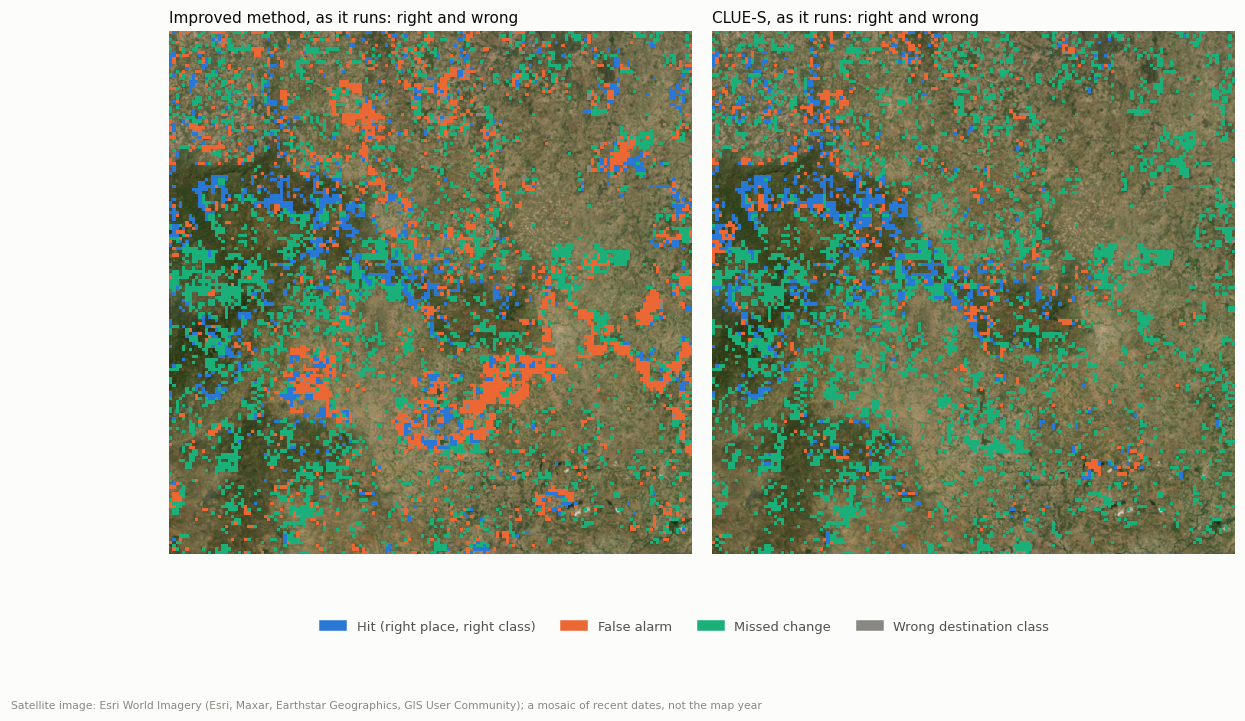

In [9]:
%matplotlib inline
# landuse_tool.change_analysis (imported by the allocator above) switches matplotlib to a
# non-display backend; this switches the notebook's inline plots back on.
ok = g & E.valid_classes(b, c)
new_obs = ok & (b != c) & ~np.any(E._past(2024) == c[None], axis=0)
VIEWS = {"Guinea": None, "Window 1 (most change)": H.busiest_window(ok & (b != c), inside=g),
         "Window 2 (most new change)": H.busiest_window(new_obs, inside=g)}
forecasts = {f"{n}, as it runs": s for n, s in as_run.items() if n != "No change"}
forecasts |= {f"{n}, same amount of change": s for n, s in same_amount.items() if n not in OURS}
LAYERS = {"Satellite image": ("satellite", None), "ESRI 2024 (start)": ("classes", b),
          "ESRI 2025 (what happened)": ("classes", c)}
for name, s in forecasts.items():
    if name.startswith("No change"):
        continue
    LAYERS[f"{name}: right and wrong"] = ("outcome", H.outcome_map(b, c, s, ok & E.valid_classes(s)))
    LAYERS[f"{name}: land cover 2025"] = ("classes", s)


def draw_layer(ax, name, view):
    kind, arr = LAYERS[name]
    cut = (lambda a: a) if view is None else (lambda a: H.crop(a, view))
    if kind == "satellite":
        H.plot_satellite(ax, prof, view, title=name)
    elif kind == "classes":
        H.plot_classes(cut(arr), name, ax, cut(g))
    else:
        H.plot_outcome_map(cut(arr), name, ax, legend=False, profile=prof, window=view)


def compare(left, right, area):
    view = VIEWS[area]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4 if view is None else 6.6), gridspec_kw={"wspace": 0.04})
    for ax, name in zip(axes, (left, right)):
        draw_layer(ax, name, view)
    kinds = {LAYERS[n][0] for n in (left, right)}
    if "outcome" in kinds:
        H.outcome_legend(fig, satellite=True, credit=False, loc="upper center", bbox_to_anchor=(0.5, 0.06))
    if "classes" in kinds:
        H.esri_class_legend(fig, set(np.unique(c[g]).tolist()), loc="upper center",
                            bbox_to_anchor=(0.5, 0.0 if "outcome" in kinds else 0.06))
    if kinds & {"outcome", "satellite"}:
        H.satellite_credit(fig, -0.08)
    plt.show()


compare("Improved method, as it runs: right and wrong", "CLUE-S, as it runs: right and wrong", "Window 2 (most new change)")

In [10]:
import ipywidgets as W
pick = lambda label, value: W.Dropdown(options=list(LAYERS), value=value, description=label,
                                       layout=W.Layout(width="560px"), style={"description_width": "50px"})
W.interact(compare,
           left=pick("Left", "Improved method, as it runs: right and wrong"),
           right=pick("Right", "MOLUSCE LR, same amount of change: right and wrong"),
           area=W.Dropdown(options=list(VIEWS), value="Window 2 (most new change)", description="Area",
                           layout=W.Layout(width="360px"), style={"description_width": "50px"}));

interactive(children=(Dropdown(description='Left', index=15, layout=Layout(width='560px'), options=('Satellite…

### All metrics (detail)

MOLUSCE's own validation metrics are computed exactly as MOLUSCE computes them
(`benchmark_scoring.molusce_metrics`; they match its reported values to four decimals). Kappa
(histogram) measures agreement in the amount of each class, kappa (location) in where classes are.

In [11]:
detail = pd.DataFrame({**{f"{n}, as it runs": {**rows[n], **BS.molusce_metrics(c, s, g & E.valid_classes(b, c, s))}
                          for n, s in as_run.items()},
                       **{f"{n}, same amount of change": {**BS.tool_row(b, c, s, g), **BS.molusce_metrics(c, s, g & E.valid_classes(b, c, s))}
                          for n, s in same_amount.items() if n not in OURS}}).T
H.show(detail.reset_index(names="Forecast 2025"), 3)

Forecast 2025,Changes observed,Changes forecast,Hits %,Misses %,Wrong hits %,False alarms %,Figure of Merit %,Producer's accuracy %,User's accuracy %,Quantity disagreement %,Allocation disagreement %,Overall accuracy %,Kappa,× random,Figure of Merit % at 1 km,Figure of Merit % at 5 km,Correctness %,Kappa (overall),Kappa (histogram),Kappa (location)
"No change, as it runs",507539.000,0.000,0.000,12.655,0.000,0.000,0.000,0.000,,6.197,6.458,87.345,0.760,,0.000,0.000,87.345,0.760,0.882,0.861
"MOLUSCE ANN, as it runs",507539.000,3043.000,0.009,12.643,0.003,0.064,0.068,0.068,11.370,6.240,6.470,87.290,0.759,1.462,0.155,0.379,87.290,0.759,0.882,0.861
"MOLUSCE LR, as it runs",507539.000,65794.000,0.501,12.099,0.055,1.084,3.644,3.956,30.518,6.200,7.039,86.762,0.749,2.437,5.551,9.990,86.762,0.749,0.882,0.848
"CLUE-S, as it runs",507539.000,249520.000,2.422,10.183,0.050,3.749,14.764,19.138,38.928,0.001,13.981,86.018,0.729,2.150,18.629,25.469,86.018,0.729,1.000,0.729
"PLUS, as it runs",507539.000,580219.000,3.021,9.472,0.161,11.285,12.621,23.876,20.885,0.187,20.731,79.082,0.594,1.501,22.726,35.546,79.082,0.594,0.996,0.596
"FLUS, as it runs",507539.000,928829.000,5.459,6.982,0.214,17.486,18.110,43.135,23.570,0.002,24.680,75.318,0.521,1.788,25.166,35.086,75.318,0.521,1.000,0.521
"Deployed method, as it runs",507539.000,500920.000,4.000,8.510,0.145,8.345,19.049,31.611,32.028,0.083,16.916,83.001,0.670,2.187,24.425,34.834,83.001,0.670,0.998,0.671
"Improved method, as it runs",507539.000,500920.000,4.235,8.297,0.122,8.132,20.374,33.468,33.910,0.083,16.468,83.448,0.679,2.339,25.229,35.318,83.448,0.679,0.998,0.680
"MOLUSCE ANN, same amount of change",507539.000,500920.000,2.329,10.026,0.300,9.861,10.344,18.404,18.647,0.083,20.103,79.813,0.608,1.187,10.561,11.308,79.813,0.608,0.998,0.609
"MOLUSCE LR, same amount of change",507539.000,500920.000,4.129,8.355,0.171,8.190,19.808,32.628,33.059,0.083,16.632,83.284,0.676,2.274,26.664,39.314,83.284,0.676,0.998,0.677


## 5 · What improved the deployed method

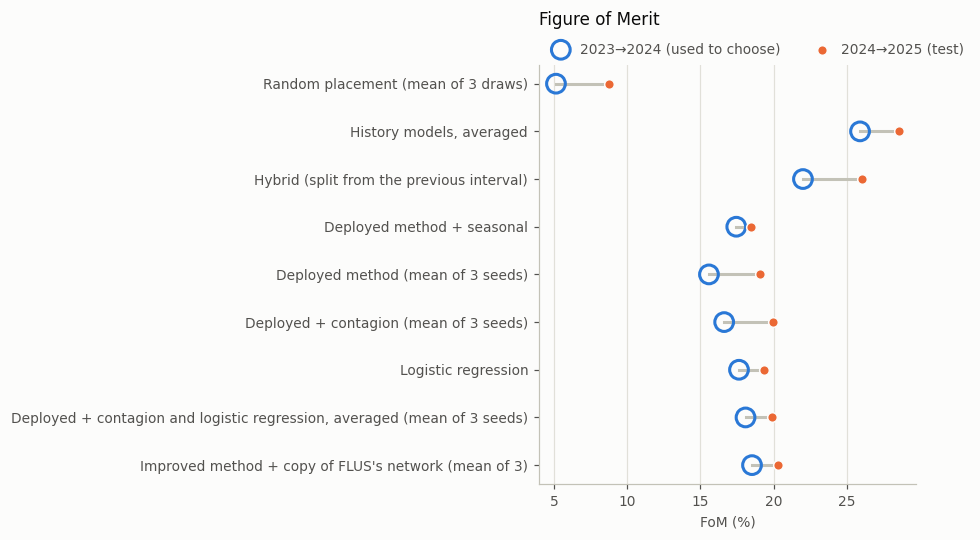

In [12]:
c8 = read("08_models").set_index("Configuration")
c7 = read("07_results").set_index("Configuration")
c9 = read("09_models").set_index("Configuration")
cols = ["FoM % 2023→2024", "FoM % 2024→2025", "Check: new-change FoM % 2024→2025", "Against the rule"]
CHOSEN = "Deployed + contagion and logistic regression, averaged (mean of 3 seeds)"
FINAL = "Improved method + copy of FLUS's network (mean of 3)"
tried = pd.concat([
    c8.loc[["Random placement (mean of 3 draws)"], cols],
    c7.loc[["History models, averaged", "Hybrid (split from the previous interval)", "Deployed method + seasonal"], cols],
    c8.loc[["Deployed method (mean of 3 seeds)", "Deployed + contagion (mean of 3 seeds)", "Logistic regression", CHOSEN], cols],
    c9.loc[[FINAL], cols]])
tried.loc[FINAL, "Against the rule"] = "improves: chosen"
tried = tried.rename_axis("Configuration").reset_index()
H.show(tried)
plot = tried.rename(columns={cols[0]: "a", cols[1]: "b"})
H.plot_dumbbell(plot, "Figure of Merit", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test)"), xlabel="FoM (%)")
plt.tight_layout(); plt.show()

**The rule** (README): settings chosen on 2023→2024, tested once on 2024→2025. An
improvement must beat the deployed method by more than the spread across random seeds (about
±0.05 points; Bouthillier et al. 2021), beat random placement (Pontius et al. 2004), and pass
the flip-back check (section 2).

* **Improvement approach (history models) and hybrid** (notebooks 06–07): higher scores, but
  they fail the flip-back check.
* **Seasonal MODIS features** (notebook 07): help on 2023→2024, not on 2024→2025, also when
  standardised within each year. Not adopted.
* **Contagion features** (how much new change happened nearby last year; Rosa et al. 2013;
  notebook 08): improve, with no new data.
* **Logistic regression**, the model of MOLUSCE and CLUE-S (an insight from section 4; notebook
  08): improves. **Averaged with the Random Forest with contagion features, it is the chosen
  model: 19.9% on 2024→2025, +0.8 points over the deployed method, 2.3 times random placement.**
  It was the improved method of the first tool comparison.
* **FLUS's neural network**, reproduced in code (an insight from section 4; notebook 09, section
  4): averaged with that model, each of the three with equal weight, it improves again:
  **20.3% on 2024→2025, +1.3 points over the deployed method**, 2.3 times random placement. **This
  is now the improved method**, used in section 4 and notebook 10. The
  idea came from FLUS's 2024→2025 result, so that year is a weaker test for it; 2025→2026 is the
  independent one.
* **Checks of the chosen method:** the averaging weights are fixed, not tuned, and changing them
  moves the 2024→2025 score by 0.22 points at most (notebooks 08 and 09). On an earlier year,
  2022→2023, the method gains +0.8 points over the deployed method and passes the flip-back check
  (notebook 11, section 5).

Every step, in order, with where the idea came from: notebook 11.

## 6 · Recommendations

1. **Report the forecast with the standard set, on Guinea only:** Figure of Merit (all change)
   as the headline, with producer's and user's accuracy, quantity and allocation disagreement,
   and random placement as the floor (Pontius et al. 2004, 2008; Pontius & Millones 2011). The
   published 13.80% was scored over the bounding box.
2. **Fix the three input problems** (predictor names, dates, training area).
3. **Adopt contagion features, averaged with a logistic regression and a copy of FLUS's network:**
   20.3% on 2024→2025 (mean of 3 seeds), +1.3 points over the corrected deployed method, ahead of
   MOLUSCE, CLUE-S, PLUS and FLUS as they run (section 4). No new data.
4. **Do not adopt the improvement approach's history models or the hybrid:** their gain is
   predicted flicker. Seasonal features: not adopted (no gain on the test year, also when standardised).
5. **Keep the flip-back check in the methodology's appendix** for every future change.
6. **Confirm on 2025→2026** once ESRI publishes its 2026 map. Methods and settings are now fixed,
   so the method can be adopted now: the gain also holds on 2022→2023 (+0.8 points) and does not
   depend on the averaging weights.
7. **Judge land-change tools by the Figure of Merit and its components, not kappa or overall
   accuracy** (section 4; Pontius & Millones 2011).
8. **The tool comparison is complete** (notebooks 00, 09, 10). Keep the two-table layout, and
   present the platform with both its accuracy and what it takes to run each tool.
9. **The copy of FLUS's network is added to the improved method** (notebook 09, section 4; decided
   24 October 2026): it passes the rule (20.3% on 2024→2025, +0.46), runs in code in about 2 minutes
   a year, needs no new data and no FLUS program. The tool comparison (section 4, notebook 10) is
   rerun with it. Every table is shown with and without the deployed method.
10. **Keep the twelve predictors; correct their labels in the methodology document** (notebook 12).
    Leaving each out in turn shows NDVI carries most of the information (about 4 points of Figure of
    Merit), then rainfall, biomass and population. Leaving out the six with no clear effect costs
    accuracy on 2024→2025; mining areas and fire, the two Guinea-specific candidates, are not
    chosen. Seven of the twelve labels in §6.2 name the wrong layer.

### References

* Bouthillier, X., et al. (2021). Accounting for variance in machine learning benchmarks.
  *Proceedings of Machine Learning and Systems* 3.
* Dietterich, T.G. (2000). Ensemble methods in machine learning. In *Multiple Classifier Systems*,
  Lecture Notes in Computer Science 1857, 1–15.
* FAO (2020). Global Forest Resources Assessment 2020: Terms and definitions. Forest Resources
  Assessment Working Paper 188. Rome.
* Liang, X., Guan, Q., Clarke, K.C., et al. (2021). Understanding the drivers of sustainable
  land expansion using a patch-generating land use simulation (PLUS) model: a case study in
  Wuhan, China. *Computers, Environment and Urban Systems* 85, 101569.
* Liu, X., Liang, X., Li, X., et al. (2017). A future land use simulation model (FLUS) for simulating
  multiple land use scenarios by coupling human and natural effects. *Landscape and Urban Planning*
  168, 94–116.
* Moulds, S., Buytaert, W., Mijic, A. (2015). An open and extensible framework for spatially explicit
  land use change modelling: the lulcc R package. *Geoscientific Model Development* 8, 3215–3229.
* Pontius, R.G. Jr. (2018). Criteria to confirm models that simulate deforestation and carbon
  disturbance. *Land* 7(3), 105.
* Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for
  spatially explicit land-change models. *Ecological Modelling* 179(4), 445–461.
* Pontius, R.G. Jr., Boersma, W., Castella, J.-C., et al. (2008). Comparing the input, output,
  and validation maps for several models of land change. *Annals of Regional Science* 42(1), 11–37.
* Pontius, R.G. Jr., Millones, M. (2011). Death to Kappa: birth of quantity disagreement and
  allocation disagreement for accuracy assessment. *International Journal of Remote Sensing*
  32(15), 4407–4429.
* Pontius, R.G. Jr., Peethambaram, S., Castella, J.-C. (2011). Comparison of three maps at multiple
  resolutions: a case study of land change simulation in Cho Don District, Vietnam. *Annals of the
  Association of American Geographers* 101(1), 45–62.
* Pontius, R.G. Jr., Schneider, L.C. (2001). Land-cover change model validation by an ROC method for
  the Ipswich watershed, Massachusetts, USA. *Agriculture, Ecosystems & Environment* 85, 239–248.
* Pontius, R.G. Jr., Si, K. (2014). The total operating characteristic to measure diagnostic
  ability for multiple thresholds. *International Journal of Geographical Information Science*
  28(3), 570–583.
* Pontius, R.G. Jr., Krithivasan, R., Sauls, L., Yan, Y., Zhang, Y. (2017). Methods to summarize
  change among land categories across time intervals. *Journal of Land Use Science* 12(4), 218–230.
* Rosa, I.M.D., Purves, D., Souza, C. Jr., Ewers, R.M. (2013). Predictive modelling of
  contagious deforestation in the Brazilian Amazon. *PLoS ONE* 8(10), e77231.
* Verburg, P.H., Soepboer, W., Veldkamp, A., et al. (2002). Modeling the spatial dynamics of
  regional land use: the CLUE-S model. *Environmental Management* 30(3), 391–405.
* Verburg, P.H., Overmars, K.P. (2009). Combining top-down and bottom-up dynamics in land use
  modeling: exploring the future of abandoned farmlands in Europe with the Dyna-CLUE model.
  *Landscape Ecology* 24(9), 1167–1181.

In [13]:
comparison.to_csv(S / "00_comparison.csv")
detail.round(4).to_csv(S / "00_benchmark_detail.csv")
print("Saved", (S / "00_comparison.csv").relative_to(H.ROOT), "and 00_benchmark_detail.csv")

Saved outputs\summary\00_comparison.csv and 00_benchmark_detail.csv
